# Paso 1: Carga de los datos

In [2]:
# 1) Clonado del repositorio donde está la información punto de partida del análisis
!git clone https://github.com/cdg-e/DSC3_Proyecto.git
%cd DSC3_Proyecto
# 2) Búsqueda de archivo .csv
!ls -R | head -40

Cloning into 'DSC3_Proyecto'...
remote: Enumerating objects: 25, done.
remote: Counting objects: 100% (25/25), done.
remote: Compressing objects: 100% (23/23), done.
remote: Total 25 (delta 8), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (25/25), 1004.17 KiB | 6.48 MiB/s, done.
Resolving deltas: 100% (8/8), done.
/content/DSC3_Proyecto
.:
ag_news
README.md

./ag_news:
ag_news_test.csv
ag_news_train.csv


In [3]:
from pathlib import Path
import pandas as pd

# Usamos Path(".") ya que nos encontramos dentro de la carpeta clonada DSC3_Proyecto
BASE = Path(".")
DATASET = "ag_news"

def cargar(dataset: str = DATASET):
    tr = pd.read_csv(BASE / dataset / f"{dataset}_train.csv")
    te = pd.read_csv(BASE / dataset / f"{dataset}_test.csv")
    return tr, te

train_df, test_df = cargar()

# Chequeo del dataset cargado (train)
print(train_df.shape, test_df.shape)
print(train_df["label"].value_counts())

print(f"Dataset: {DATASET}")
print(f"Train: {train_df.shape} | Test: {test_df.shape}")
print("Clases:", sorted(train_df['label'].unique()))
print(train_df.head())

(8000, 2) (2000, 2)
label
Sci_Tech    2000
Business    2000
Sports      2000
World       2000
Name: count, dtype: int64
Dataset: ag_news
Train: (8000, 2) | Test: (2000, 2)
Clases: ['Business', 'Sci_Tech', 'Sports', 'World']
                                                text     label
0  Red Hat Appoints New CFO. September 2, 2004 --...  Sci_Tech
1  Sprint, SBC In Hotspot Roaming Deal. Sprint an...  Sci_Tech
2  Radio Outage Grounds West Coast Flights. Airpo...  Business
3  Hollywood lawsuits to strike Net pirates. Holl...  Sci_Tech
4  Custis Takes Control. Family and Tony Robbins ...    Sports


In [4]:
# Verificación rápida de los datos
print(train_df.shape)                 # cuántas filas y columnas
print(train_df.columns.tolist())      # nombres de los campos (col) ['text', 'label']
print(train_df.isna().sum())          # valores nulos por columna
print(train_df.duplicated().sum())    # se detecta si hay filas duplicadas y las cuenta
print(train_df['label'].value_counts()) #conteo de registros por etiqueta
train_df.head()

(8000, 2)
['text', 'label']
text     0
label    0
dtype: int64
0
label
Sci_Tech    2000
Business    2000
Sports      2000
World       2000
Name: count, dtype: int64


,text,label
0,"Red Hat Appoints New CFO. September 2, 2004 --...",Sci_Tech
1,"Sprint, SBC In Hotspot Roaming Deal. Sprint an...",Sci_Tech
2,Radio Outage Grounds West Coast Flights. Airpo...,Business
3,Hollywood lawsuits to strike Net pirates. Holl...,Sci_Tech
4,Custis Takes Control. Family and Tony Robbins ...,Sports


# Paso 2

Inspección previa del texto crudo para detectar lo que se debe eliminar

In [5]:
import re

patrones = {
    "Tags HTML":              r"<[^>]+>",
    "URLs":                   r"http\S+|www\.\S+",
    "Entidades (&amp; &lt;)": r"&#?\w+;",
    "Restos tipo #39;":       r"#\d+;",
    "Números":                r"\d+",
    "Símbolos raros":         r"[^A-Za-z0-9\s.,;:'\"!?()\-]",
}

auditoria = pd.DataFrame({
    "Patrón": list(patrones),
    "Docs afectados": [train_df["text"].str.contains(p, regex=True).sum() for p in patrones.values()],
})
auditoria["% del corpus"] = (auditoria["Docs afectados"] / len(train_df) * 100).round(1)
display(auditoria)

# Ejemplos reales de cada patrón (la parte más convincente)
for nombre, p in patrones.items():
    muestra = train_df.loc[train_df["text"].str.contains(p, regex=True), "text"].head(2)
    print(f"\n{nombre}:")
    for t in muestra:
        m = re.search(p, t)
        ini = max(m.start() - 30, 0)
        print("   ...", t[ini:m.end() + 30], "...")

,Patrón,Docs afectados,% del corpus
0,Tags HTML,0,0.0
1,URLs,135,1.7
2,Entidades (&amp; &lt;),359,4.5
3,Restos tipo #39;,2132,26.6
4,Números,4681,58.5
5,Símbolos raros,2876,35.9



Tags HTML:

URLs:
   ... s) - PepsiCo Inc. &lt;A HREF="http://www.investor.reuters.com/FullQuote.aspx?ticker=PEP.N target=/stocks/quickinfo/full ...
   ... ate-Palmolive Co. &lt;A HREF="http://www.investor.reuters.com/FullQuote.aspx?ticker=CL.N target=/stocks/quickinfo/full ...

Entidades (&amp; &lt;):
   ...  at least another six months. &lt;FONT face="verdana,MS Sans Ser ...
   ... two political prisoner: party &lt;b&gt;...&lt;/b&gt;. YANGON : M ...

Restos tipo #39;:
   ... rt. Two of the European Union #39;s landmark antitrust decisions ...
   ... d something the Mariners hadn #39;t done in nearly eight years.  ...

Números:
   ... t Appoints New CFO. September 2, 2004 -- (WEB HOST INDUSTRY R ...
   ... t. Two of the European Union #39;s landmark antitrust decision ...

Símbolos raros:
   ... rt. Two of the European Union #39;s landmark antitrust decisi ...
   ... d something the Mariners hadn #39;t done in nearly eight year ...


In [6]:
# Búsqueda de caracteres raros, acá se seleccion 15 filas al azar de los registros (datos crudos)
# Objetivo: visualizar filas de texto para una inspección visual rápida

for t in train_df["text"].sample(15, random_state=42):
    print("-", t[:200])

- Earnings alert: Salesforce quarterly revenue rises. Plus: Write-downs widen DirecTV's loss...Time Warner net income slips...Cell phone unit shores up Verizon.
- Schumacher Wins Japanese Grand Prix for 13th Victory of Season. World champion Michael Schumacher won the Japanese Grand Prix to give his Ferrari team a record-tying 15th victory in 17 Formula One rac
- Crimson find the range. PRINCETON, N.J. -- You've got to wonder what kind of team Harvard would be if the Crimson got into the flow of their games earlier.
- A Giant collapse Crushing loss to LA in ninth inning dims playoff &lt;b&gt;...&lt;/b&gt;. Los Angeles - -- JT Snow never turned to see Steve Finley #39;s grand slam land softly in the right-field pavi
- Philippines issues new warning against job-seekers heading for Iraq (AFP). AFP - Philippine President Gloria Arroyo's government has issued a fresh warning to Filipino job-seekers trying to fly to Ira
- Conexant Shares Plunge on 4Q Loss. Conexant Systems Inc. shares slid i

In [19]:
# Objetivo: contabilizar catacteres no alfa numéricos
from collections import Counter

chars = Counter("".join(train_df["text"]))
raros = {c: n for c, n in chars.items() if not (c.isalnum() or c == " ")}
pd.Series(raros).sort_values(ascending=False)

,0
.,23249
",",11042
-,9366
;,5832
#,3155
(,2741
),2716
',2164
&,1770
/,1454


In [7]:
#Objetivo: buscar ejemplos donde hay # (muestra de 4 ejemplos)
train_df.loc[train_df["text"].str.contains("#"), "text"].head(4).tolist()

['WorldCom, Microsoft cases before EU court. Two of the European Union #39;s landmark antitrust decisions against US companies are in court this week as WorldCom Inc. seeks a moral victory and Microsoft Corp.',
 'Homer-happy Mariners end skid. A four-pitch sequence in the fifth inning Friday night produced something the Mariners hadn #39;t done in nearly eight years. Miguel Olivo hit a home run to left-center field.',
 'Chinese astronauts to wear lighter outfits. China has developed a light and removable spacesuit for its astronauts set to embark on China #39;s second manned space mission scheduled for next September.',
 'Athletics: Shaheen record run lifts after-show party. For Saif Saaeed Shaheen, the Memorial Van Damme in the Stade Roi Baudouin last night was the Lord Mayor #39;s Show, not after it. He made the most of it, steeplechasing in all his']

In [8]:
#Objetivo: buscar ejemplos donde hay & (muestra de 4 ejemplos)
train_df.loc[train_df["text"].str.contains("&"), "text"].head(4).tolist()

['Verizon, Qwest Ask Court to Block Rules. Verizon and Qwest asked a federal court to block temporary rules forcing the companies to lease phone lines to rivals for at least another six months. &lt;FONT face="verdana,MS Sans Serif,arial,helvetica" size="-2" color="#666666"&gt;&lt;B&gt;-Reuters&lt;/B&gt;&lt;/FONT&gt;',
 'Myanmar #39;s military govt frees number two political prisoner: party &lt;b&gt;...&lt;/b&gt;. YANGON : Myanmar #39;s military government has freed the country #39;s second most prominent political prisoner, student democracy leader Min Ko Naing, an opposition party spokesman told AFP.',
 'Death toll rises to 66 from Chinese coal mine explosion as &lt;b&gt;...&lt;/b&gt;. Rescue workers pulled more bodies out of a mine shaft choked with toxic fumes Friday as the death toll in China #39;s worst mining accident this year rose to 66, with 82 workers missing and feared dead.',
 'Australian Football: Melbourne sidelined as Brisbane and Port &lt;b&gt;...&lt;/b&gt;. The Austral

In [9]:
#Objetivo: buscar ejemplos donde hay = (muestra de 4 ejemplos)
train_df.loc[train_df["text"].str.contains("="), "text"].head(4).tolist()

['Verizon, Qwest Ask Court to Block Rules. Verizon and Qwest asked a federal court to block temporary rules forcing the companies to lease phone lines to rivals for at least another six months. &lt;FONT face="verdana,MS Sans Serif,arial,helvetica" size="-2" color="#666666"&gt;&lt;B&gt;-Reuters&lt;/B&gt;&lt;/FONT&gt;',
 'PepsiCo Says Profit Rises on Tax Benefits. NEW YORK (Reuters) - PepsiCo Inc. &lt;A HREF="http://www.investor.reuters.com/FullQuote.aspx?ticker=PEP.N target=/stocks/quickinfo/fullquote"&gt;PEP.N&lt;/A&gt;, the world\'s No. 2 soft drink company, said on Thursday quarterly profit rose due to $221 million in tax benefits and strong performances from its key Frito-Lay snack and North American beverage businesses.',
 'Colgate Warns, Shares Hit 4-Year Low. By Brad Dorfman CHICAGO (Reuters) - Colgate-Palmolive Co. &lt;A HREF="http://www.investor.reuters.com/FullQuote.aspx?ticker=CL.N target=/stocks/quickinfo/fullquote"&gt;CL.N&lt;/A&gt; on Monday issued its first formal profit 

In [10]:
#Objetivo: buscar ejemplos donde hay &+texto
for t in train_df.loc[train_df["text"].str.contains("&"), "text"].head(5):
    i = t.index("&")
    print("...", t[max(i-30, 0):i+60], "...")

...  at least another six months. &lt;FONT face="verdana,MS Sans Serif,arial,helvetica" size=" ...
... two political prisoner: party &lt;b&gt;...&lt;/b&gt;. YANGON : Myanmar #39;s military gove ...
... hinese coal mine explosion as &lt;b&gt;...&lt;/b&gt;. Rescue workers pulled more bodies ou ...
... idelined as Brisbane and Port &lt;b&gt;...&lt;/b&gt;. The Australian Football League Grand ...
... lances is Within the Realm of &lt;b&gt;...&lt;/b&gt;. THE global economy is slowly recover ...


In [20]:
# Objetivo: conteo de elementos entre delimitadores
entre = Counter(re.findall(r"&lt;(.*?)&gt;", " ".join(train_df["text"])))
entre.most_common(10)

[('/b', 189),
 ('b', 178),
 ('/A', 149),
 ('p', 35),
 ('/p', 35),
 ('FONT face="verdana,MS Sans Serif,arial,helvetica" size="-2" color="#666666"',
  26),
 ('B', 26),
 ('/B', 15),
 ('/FONT', 15),
 ('/font', 11)]

# Paso 3
Paso 3a: Setup de SpaCy, descarga del modelo en inglés

In [21]:
!python -m spacy download en_core_web_sm


  Using cached en_core_web_sm-3.8.0-py3-none-any.whl (12.8 MB)
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [13]:
# Testeo de que se cargó bien spacy
import spacy

nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])
doc = nlp("this is a document") #esta línea es la frase que vá a tokenizar
print([token.lemma_ for token in doc])


['this', 'be', 'a', 'document']


Paso 3b: Limpieza y Normalización

In [22]:
# Definición de proceso de limpieza

def clean_regex(text): #limpieza
    text = str(text)
    text = re.sub(r"&?(#\d+|quot|amp|lt|gt|nbsp);", r"&\1;", text)  # repara entidades sin '&'
    text = html.unescape(text)                                       # &lt;b&gt; -> <b>
    text = re.sub(r"<[^>]*>", " ", text)                             # tags HTML
    text = re.sub(r"<[^>]*$", " ", text)                             # tag cortado al final
    text = re.sub(r"http\S+|www\.\S+", " ", text)                    # URLs
    text = re.sub(r"[^A-Za-z'\s]", " ", text)                        # solo letras y apóstrofes
    return re.sub(r"\s+", " ", text).strip()

# Definición de proceso de normalización

def preprocess_text(text):
    """Pipeline: regex -> lematización SpaCy -> minúsculas."""
    doc = nlp(clean_regex(text))
    return " ".join(tok.lemma_.lower() for tok in doc if tok.is_alpha and len(tok) > 1)

In [24]:
# Aplicación de los procesos de limpieza y normalización a train y test

from tqdm.auto import tqdm
tqdm.pandas()
import html

train_df["text_clean"] = train_df["text"].progress_apply(preprocess_text)
test_df["text_clean"]  = test_df["text"].progress_apply(preprocess_text)

# Se guarda dentro del repositorio las tablas con texto limpio y normalizado (trazabilidad)
out = BASE / DATASET
train_df.to_csv(out / "train_clean.csv", index=False)
test_df.to_csv(out / "test_clean.csv", index=False)

# Verificaciones
print("Train:", train_df.shape, "| Test:", test_df.shape)
print("Textos vacíos -> train:", (train_df["text_clean"] == "").sum(),
      "| test:", (test_df["text_clean"] == "").sum())
print("\nClases en test:")
print(test_df["label"].value_counts())
test_df[["text", "text_clean"]].sample(3, random_state=1)

  0%|          | 0/8000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

Train: (8000, 3) | Test: (2000, 3)
Textos vacíos -> train: 0 | test: 0

Clases en test:
label
World       500
Business    500
Sports      500
Sci_Tech    500
Name: count, dtype: int64


,text,text_clean
674,Social Security Reform a Boon for Funds? (Reut...,social security reform boon for funds reuters ...
1699,Britain Edges U.S. for 400M Relay Gold (AP). A...,britain edges for relay gold ap ap stymie by s...
1282,Hodge called up as Ponting returns home. Victo...,hodge call up as ponte return home victorian b...


• Se verifica que el número de registros en Train y Test permanecen iguales como así también el nro de columnas ✓

• Se verifica que el número de registro por clases en el dataset de entrenamiento sigue igual ✓

• No quedaron filas vacías posterior al proceso de limpieza, es decir que no había noticias con contenido vacío de palabras.



# Paso 4: pipeline con TF-IDF

## Objetivo
Vectorizar y clasificar en un solo objeto.
Se usa una validación cruzada que consiste en dividir los datos de entrenamiento en 5 partes, tal que se entrena con 4 y prueba con la quinta. Se rotan los conjuntos y en cada rotación se hace un ajuste de vectorizado.


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold

X_train = train_df["text_clean"]
y_train = train_df["label"]

# Nota: en este paso NO se usa test_df

# 1) Mirar qué produce el vectorizador (solo informativo)
vec = TfidfVectorizer(max_features=5000, ngram_range=(1, 1))
M = vec.fit_transform(X_train)
print("Matriz TF-IDF:", M.shape, "| densidad:", f"{M.nnz / (M.shape[0]*M.shape[1]):.2%}")

# 2) Pipeline baseline: TF-IDF + regresión logística
baseline = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 1))),
    ("clf", LogisticRegression(max_iter=1000, random_state=42)),
])

# 3) Validación cruzada de 5 particiones, solo sobre el train
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(baseline, X_train, y_train, cv=cv, scoring="f1_macro")

print("F1 macro por partición:", scores.round(3))
print(f"Media: {scores.mean():.3f} (± {scores.std():.3f})")

Matriz TF-IDF: (8000, 5000) | densidad: 0.54%
F1 macro por partición: [0.88  0.88  0.879 0.897 0.882]
Media: 0.884 (± 0.007)


## Conclusiones
• Matriz (8000, 5000), densidad 0,54%
En ésta matriz, cada fila es un texto del dataset de entrenamiento (8000 registros) y cada columna corresponde a una palabra del vocabulario del top 5000.
De todas los registros, se toman las 5000 palabras que más se repiten, luego para cada fila de texto se tiene una columna por cada una de estas 5000 palabras donde se coloca un 1 si dicha palabra forma parte del texto de la fila en cuestión y un cero si no lo hace.
Esto tiene coherencia, los registros tienen de media 36 tokens, y varios se repiten o quedan fuera del vocabulario de 5.000.

• F1 macro medio 0,884 (± 0,007). Se lee con las dos referencias que dejé antes:
•	Al haberse particionado el dataset train en 4 partes, si el valor estuviera cerca del 25% es azar, y en este caso no pasa.
•	Está lejos de ser 100%.
•	El desvío de 0,007 es chico y las cinco particiones dan entre 0,879 y 0,897. El resultado no depende de cómo se parta el train, y la estimación es estable.
Es importante mencionar que aun no se ha trabajado con el dataset de testeo.


Paso 4.1: EDA técnico

count    8000.000000
mean       35.868375
std         9.321865
min         6.000000
25%        30.000000
50%        35.000000
75%        41.000000
max       136.000000
Name: n_tokens, dtype: float64
Documentos vacíos tras la limpieza: 0

Percentil 95 (max_len): 50
Documentos que quedarían truncados: 368


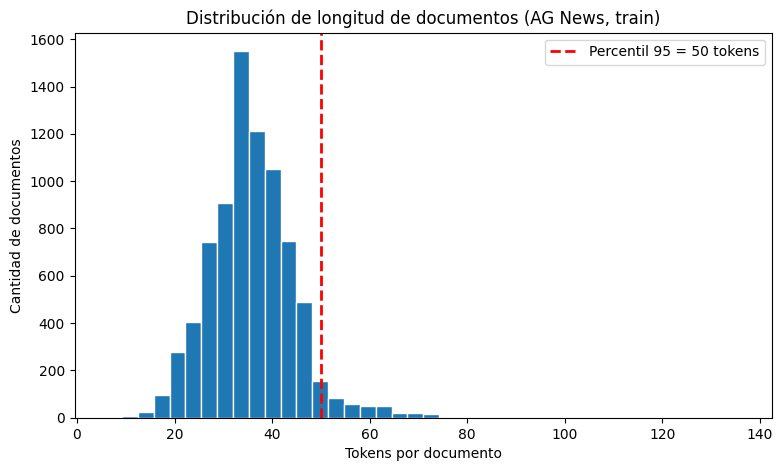

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# 1) Conteo de tokens por documento (sobre texto ya limpio)
train_df["n_tokens"] = train_df["text_clean"].str.split().str.len()

print(train_df["n_tokens"].describe())
print("Documentos vacíos tras la limpieza:", (train_df["n_tokens"] == 0).sum())

# 2) Percentil 95 = max_len
p95 = int(np.ceil(np.percentile(train_df["n_tokens"], 95)))
print(f"\nPercentil 95 (max_len): {p95}")
print(f"Documentos que quedarían truncados: {(train_df['n_tokens'] > p95).sum()}")

# 3) Histograma con la línea del percentil 95
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(train_df["n_tokens"], bins=40, edgecolor="white")
ax.axvline(p95, color="red", linestyle="--", linewidth=2, label=f"Percentil 95 = {p95} tokens")
ax.set_xlabel("Tokens por documento")
ax.set_ylabel("Cantidad de documentos")
ax.set_title("Distribución de longitud de documentos (AG News, train)")
ax.legend()
plt.savefig("hist_tokens.png", dpi=150, bbox_inches="tight")  # lo usamos después en el PDF
plt.show()

Conclusión: de las 8000 filas del dataset de entrenamiento, se cuenta cuantos tokens quedó en cada registro y de eso se tiene los valores estadísticos. Es decir que cada registro tiene aproximadamente 36 token.

Paso 4.2: N-gramas

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

def top_ngrams(corpus, n=2, k=20, stop_words=None):
    vec = CountVectorizer(ngram_range=(n, n), stop_words=stop_words)
    X = vec.fit_transform(corpus)                 # matriz documentos x n-gramas
    conteos = np.asarray(X.sum(axis=0)).ravel()   # suma de cada columna
    tabla = pd.DataFrame({"ngrama": vec.get_feature_names_out(), "frecuencia": conteos})
    return tabla.sort_values("frecuencia", ascending=False).head(k).reset_index(drop=True)

# Con stop-words (tal como queda el corpus)
display(top_ngrams(train_df["text_clean"], n=2))
display(top_ngrams(train_df["text_clean"], n=3))

# Sin stop-words (más informativo del contenido)
display(top_ngrams(train_df["text_clean"], n=2, stop_words="english"))
display(top_ngrams(train_df["text_clean"], n=3, stop_words="english"))

,ngrama,frecuencia
0,of the,1411
1,in the,1383
2,for the,609
3,ap ap,529
4,to the,485
5,on the,462
6,new york,419
7,at the,395
8,have be,335
9,the world,308


,ngrama,frecuencia
0,new york reuters,158
1,the united states,148
2,one of the,107
3,ap ap the,85
4,for the first,71
5,the first time,71
6,quote profile research,69
7,kill at least,57
8,be expect to,56
9,the world large,55


,ngrama,frecuencia
0,ap ap,529
1,new york,419
2,reuters reuters,261
3,oil price,192
4,united states,166
5,york reuters,158
6,prime minister,139
7,afp afp,134
8,official say,129
9,say thursday,102


,ngrama,frecuencia
0,new york reuters,158
1,quote profile research,69
2,boston red sox,37
3,high oil price,28
4,securities exchange commission,26
5,york reuters stock,26
6,press canadian press,26
7,canadian press canadian,26
8,prime minister ariel,26
9,minister ariel sharon,25


Permite ver qué palabras se repite más (frecuencia de aparición).
Desafíos: los “stop-words” son contabilizados y suelen ser un número alto
• Se verifica que no aparecieron términos detectados en el paso 2 de pre limpieza.
• Sí aparecen términos extraños como “ap” o “co” que son palabras del texto original, no son “stop-words” e interfieren la estadística de frecuencia de aparición sin aportar significado para correlacionar con la clasificación de las noticias (desafío).
• En los textos aparece “ap”, “afp” y es un riesgo/desafío para la clasificación.
• Términos como “Wal-Mart” se convierte a “wal mart” y es un riesgo para la clasificación porque se altera el nombre propio.


Paso 4.3: top 50 de palabras

Stop-words en el top 50: 36 de 50 (72%)
Palabras con contenido: ['new', 'reuters', 'ap', 'year', 'company', 'world', 'win', 'report', 'oil', 'monday', 'game', 'wednesday', 'thursday', 'tuesday']


,palabra,frecuencia,es_stopword
0,the,13698,True
1,to,7976,True
2,of,6578,True
3,in,6365,True
4,be,4673,True
5,and,4637,True
6,on,3774,True
7,for,3410,True
8,have,2422,True
9,say,1975,True


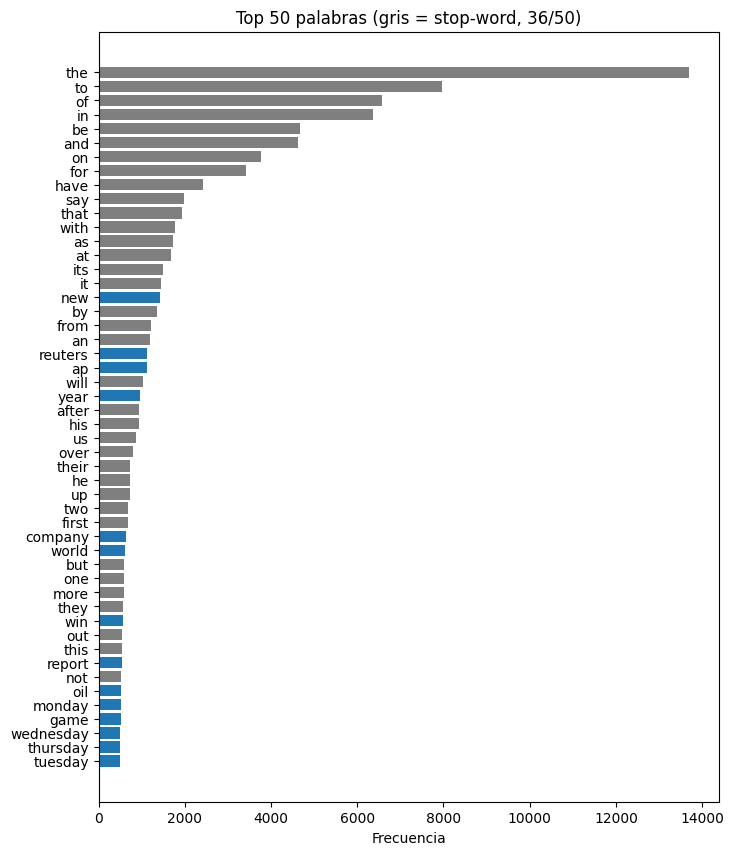

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer

# 1) Frecuencia de cada palabra en todo el corpus
vec = CountVectorizer()
X = vec.fit_transform(train_df["text_clean"])
freq = pd.DataFrame({
    "palabra": vec.get_feature_names_out(),
    "frecuencia": np.asarray(X.sum(axis=0)).ravel(),
})
top50 = freq.sort_values("frecuencia", ascending=False).head(50).reset_index(drop=True)

# 2) ¿Cuántas son stop-words? (lista de SpaCy)
stop_words = nlp.Defaults.stop_words
top50["es_stopword"] = top50["palabra"].isin(stop_words)
n_stop = int(top50["es_stopword"].sum())

print(f"Stop-words en el top 50: {n_stop} de 50 ({n_stop/50:.0%})")
print("Palabras con contenido:", top50.loc[~top50["es_stopword"], "palabra"].tolist())
display(top50)

# 3) Gráfico (gris = stop-word, azul = palabra con contenido)
fig, ax = plt.subplots(figsize=(8, 10))
colores = ["tab:gray" if s else "tab:blue" for s in top50["es_stopword"]]
ax.barh(top50["palabra"][::-1], top50["frecuencia"][::-1], color=colores[::-1])
ax.set_xlabel("Frecuencia")
ax.set_title(f"Top 50 palabras (gris = stop-word, {n_stop}/50)")
plt.savefig("top50_palabras.png", dpi=150, bbox_inches="tight")
plt.show()

Resultados:
Stop-words en el top 50: 36 de 50 (72%)
###Palabras con contenido: ['new', 'reuters', 'ap', 'year', 'company', 'world', 'win', 'report', 'oil', 'monday', 'game', 'wednesday', 'thursday', 'tuesday']


# Paso 5: Grid Search

## Objetivo
La diferencia con el paso 4 es que en vez de hacer el vectorizado con el top de 5000 palabras, se prueban distintas configuraciones.
Max_features	Se prueba con 2000, 5000 y 10000 palabras. Permite evaluar si usar más palabras en el top ayuda.
Ngram_range	Palabras sueltas versus sueltas de a pares
Ruido	Evaluar si quitar stop-words ayuda.
ap, reuters, afp y los días
Se basa en lo estudiado en la preentrega 2 donde se llegó a la conclusión que las stop-words dominaban el top 50 y ap, reuters y días de la semana son ruido (pasos 4.1, .2 y .3 de esta sección).
En esta etapa lo detectado como posibles errores se elimina para evaluar si hay mejoras en el modelado.
Para ello, se hace lo siguiente:
1.	Se define las 4 variantes de la política de ruido (A, B, C, D).
2.	Para cada variante, se prueba las 6 combinaciones de max_features × ngram_range. En total son 24 pruebas.
3.	Cada prueba se evalúa con validación cruzada dentro del train, igual que en el Paso 4.
4.	Se imprime una tabla con el F1 de cada una.


In [30]:
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Aseguramos la definición de las variables de entrenamiento para evitar el NameError
X_train = train_df["text_clean"]
y_train = train_df["label"]

# Política de ruido: lo que identificaste en el EDA del train
FUENTES = ["ap", "reuters", "afp"]
DIAS = ["monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"]
RUIDO = FUENTES + DIAS

POLITICAS = {
    "A: sin filtro":                  None,
    "B: stop-words":                  "english",
    "C: fuentes y dias":              RUIDO,
    "D: stop-words + fuentes y dias": list(ENGLISH_STOP_WORDS.union(RUIDO)),
}

grilla = {
    "tfidf__max_features": [2000, 5000, 10000],
    "tfidf__ngram_range":  [(1, 1), (1, 2)],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

resultados, mejores = [], {}
for nombre, sw in POLITICAS.items():
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(stop_words=sw)),
        ("clf", LogisticRegression(max_iter=1000, random_state=42)),
    ])
    gs = GridSearchCV(pipe, grilla, cv=cv, scoring="f1_macro", n_jobs=-1)
    gs.fit(X_train, y_train)
    mejores[nombre] = gs

    r = pd.DataFrame(gs.cv_results_)[["param_tfidf__max_features",
                                      "param_tfidf__ngram_range",
                                      "mean_test_score", "std_test_score"]]
    r.columns = ["max_features", "ngram_range", "f1_macro", "desvio"]
    r.insert(0, "politica", nombre)
    resultados.append(r)
    print(f"{nombre}: mejor F1 = {gs.best_score_:.3f}  con {gs.best_params_}")

tabla = pd.concat(resultados).sort_values("f1_macro", ascending=False).reset_index(drop=True)
display(tabla.round(3))

A: sin filtro: mejor F1 = 0.885  con {'tfidf__max_features': 10000, 'tfidf__ngram_range': (1, 1)}
B: stop-words: mejor F1 = 0.888  con {'tfidf__max_features': 5000, 'tfidf__ngram_range': (1, 1)}
C: fuentes y dias: mejor F1 = 0.882  con {'tfidf__max_features': 10000, 'tfidf__ngram_range': (1, 1)}
D: stop-words + fuentes y dias: mejor F1 = 0.886  con {'tfidf__max_features': 10000, 'tfidf__ngram_range': (1, 1)}


,politica,max_features,ngram_range,f1_macro,desvio
0,B: stop-words,5000,"(1, 1)",0.888,0.006
1,B: stop-words,10000,"(1, 2)",0.888,0.007
2,B: stop-words,10000,"(1, 1)",0.887,0.005
3,B: stop-words,5000,"(1, 2)",0.887,0.007
4,D: stop-words + fuentes y dias,10000,"(1, 1)",0.886,0.008
5,A: sin filtro,10000,"(1, 1)",0.885,0.005
6,D: stop-words + fuentes y dias,10000,"(1, 2)",0.885,0.006
7,D: stop-words + fuentes y dias,5000,"(1, 1)",0.884,0.007
8,A: sin filtro,5000,"(1, 1)",0.884,0.007
9,D: stop-words + fuentes y dias,5000,"(1, 2)",0.883,0.008


• max_features
Lo que se vé: 2.000 rinde peor (0,861 a 0,875) que 5.000 o 10.000 (0,878 a 0,888)
Interpretación: 2.000 palabras es poco para el modelo.
•ngram_range
En 12 comparaciones de unigramas contra bigramas, en ninguno los bigramas superan por más de 0,001.
Interpretación: los pares de palabras no aportan valor en este corpus. En 6 de las 12 empeoran un poco el modelado.
• stop_words (B vs A)
0,888 vs. 0,884 con 5.000; 0,887 vs. 0,885 con 10.000
Interpretación: Una mejora de 0,002 a 0,004, dentro del ruido
• Fuentes y días (A vs. C, B vs. D)
Removerlos baja entre 0,002 y 0,004.
Interpretación: no es una mejora significativa
En base a las conclusiones se adopta la política B (stop-words), max_features=5000, ngram_range=(1,1), con F1 = 0,888 ± 0,006. Basado en:
-	Es la de mayor F1 nominal
-	Es la opción más simple: unigramas y solo 5.000 columnas, sin necesidad de bigramas ni de un vocabulario más grande.
-	Quitar las stop-words reduce ruido y es coherente con lo que mostró el EDA (72% del top 50).
Se eligió TF-IDF con unigramas, max_features=5000 y filtro de stop-words por ser la configuración nominalmente mejor (F1 = 0,888) y la más simple.


Paso 6: evaluación del test

Configuración: {'tfidf__max_features': 5000, 'tfidf__ngram_range': (1, 1)}
              precision    recall  f1-score   support

    Business      0.849     0.866     0.857       500
    Sci_Tech      0.878     0.874     0.876       500
      Sports      0.949     0.962     0.955       500
       World      0.915     0.888     0.902       500

    accuracy                          0.897      2000
   macro avg      0.898     0.897     0.898      2000
weighted avg      0.898     0.897     0.898      2000



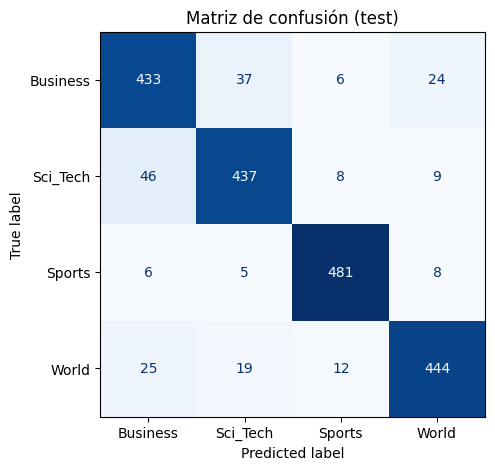

Business : company, oil, profit, billion, economy, fund, buy, corp, executive, insurance
Sci_Tech : space, internet, scientist, software, microsoft, nasa, computer, online, technology, apple
Sports   : team, coach, cup, league, win, season, player, game, football, night
World    : iraq, president, afp, nuclear, minister, kill, leader, election, israel, military


In [31]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Configuración elegida
ELEGIDA = "B: stop-words"
modelo = mejores[ELEGIDA].best_estimator_
print("Configuración:", mejores[ELEGIDA].best_params_)

# Evaluación final: SE HACE UNA SOLA VEZ
X_test, y_test = test_df["text_clean"], test_df["label"]
pred = modelo.predict(X_test)
print(classification_report(y_test, pred, digits=3))

# Matriz de confusión
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Matriz de confusión (test)")
plt.savefig("matriz_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

# Palabras que más pesan por clase
vocab = modelo.named_steps["tfidf"].get_feature_names_out()
coefs = modelo.named_steps["clf"].coef_
for i, clase in enumerate(modelo.named_steps["clf"].classes_):
    top = vocab[coefs[i].argsort()[-10:][::-1]]
    print(f"{clase:9}: {', '.join(top)}")

Interpretación:
Las noticias cuya categoría es Sports tiene mejor resultados en el modelado.
Entre Business y Sci_Tech la diferencia (0,857 vs. 0,876) cae dentro del margen de error con 500 documentos por clase, así que no podés afirmar que Business sea “peor” que Sci_Tech. No obstante, se puede decir que son las dos más difíciles.

Matriz de confusión

•	Business y Sci_Tech son el par más confundido: 83 de los 205 errores (el 40%) son entre ellas. Eso confirma la hipótesis de que son categorías con las palabras más específicas.
•	Sports casi no se confunde: solo 19 de sus 500 documentos se clasificaron mal.


Paso 6.1: últimos análisis auxiliares

In [32]:
# ¿Cuánto pesan las firmas de agencia en el modelo?
clases = list(modelo.named_steps["clf"].classes_)
print("\nCoeficiente máximo del modelo (referencia):", round(coefs.max(), 2))
for fuente in ["reuters", "afp", "ap"]:
    if fuente in vocab:
        idx = list(vocab).index(fuente)
        print(f"{fuente:8}", dict(zip(clases, coefs[:, idx].round(2))))


Coeficiente máximo del modelo (referencia): 3.85
reuters  {'Business': np.float64(0.86), 'Sci_Tech': np.float64(0.88), 'Sports': np.float64(-1.85), 'World': np.float64(0.1)}
afp      {'Business': np.float64(-1.06), 'Sci_Tech': np.float64(-0.87), 'Sports': np.float64(-1.25), 'World': np.float64(3.17)}
ap       {'Business': np.float64(-4.15), 'Sci_Tech': np.float64(1.03), 'Sports': np.float64(1.62), 'World': np.float64(1.49)}


In [33]:
err = test_df[(y_test != pred)].copy()
err["pred"] = pred[(y_test != pred).values]
cruce = err[(err["label"] == "Sci_Tech") & (err["pred"] == "Business")]
for t in cruce["text"].head(5):
    print("-", t[:150])

- E.U. Regulators Approve Oracle's PeopleSoft Bid. European Union antitrust regulators on Tuesday cleared Oracle Corp.'s hostile $7.7 billion bid for ri
- Make hotels just like home. HOTEL operators, take note: Todays hotel guests are making a nonsense of room-pricing strategies with their aggressive, In
- Barents Sea Under Threat from Fishing, Oil (Reuters). Reuters - The Arctic Barents Sea is under threat from overfishing, oil and gas exploration and S
- Supreme Court Asked To Hear File-Sharing Arguments. The file-sharing legal battle has moved to the Supreme Court, with a group composed of labor union
- Google Founders Selling Off Stock. Google Founders Selling Off Stock Is this a sign that Google stack is overpriced? Or does it just mean that since t


Se inspeccionaron cinco errores Sci_Tech - Business (muestra pequeña, ilustrativa). Dos corresponden a empresas tecnológicas con noticias financieras (la adquisición de PeopleSoft por Oracle y la venta de acciones de los fundadores de Google), donde el vocabulario económico domina sobre el tecnológico. Esto sugiere que parte del error no es del modelo sino de la ambigüedad de las clases: son noticias que razonablemente podrían pertenecer a ambas.
Se podría evaluar si modelos que capturan contexto reducen esta confusión.


Requierements. txt

In [34]:
import sys, sklearn, pandas, numpy, spacy, matplotlib, tqdm

contenido = f"""# Python {sys.version.split()[0]}
scikit-learn=={sklearn.__version__}
pandas=={pandas.__version__}
numpy=={numpy.__version__}
spacy=={spacy.__version__}
matplotlib=={matplotlib.__version__}
tqdm=={tqdm.__version__}
# Modelo de SpaCy (se instala aparte): python -m spacy download en_core_web_sm
# Versión usada: {nlp.meta['name']} {nlp.meta['version']}
"""

with open("requirements.txt", "w") as f:
    f.write(contenido)

print(contenido)

# Python 3.13.18
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.4.6
spacy==3.8.18
matplotlib==3.10.0
tqdm==4.67.3
# Modelo de SpaCy (se instala aparte): python -m spacy download en_core_web_sm
# Versión usada: core_web_sm 3.8.0

